https://opendata.euskadi.eus/api-traffic/?api=traffic

In [1]:
import datetime as dt
import numpy as np
import pandas as pd
import requests

from dateutil import parser




In [2]:
"https://api.euskadi.eus/traffic/v1.0/flows/byDate/2025/5/17?_page=11"
#2025 5 de 17
#esto es el enlace de flow

'https://api.euskadi.eus/traffic/v1.0/flows/byDate/2025/5/17?_page=11'

In [3]:
df_correo=pd.read_csv("dataframede.csv")


dia_correo=[x.replace("-","/") for x in df_correo["Fecha"][0:len(df_correo["Fecha"])]]
dia_correo #saco del csv todos los dias que hibo noticia

['2025/05/28',
 '2025/05/19',
 '2025/05/19',
 '2025/05/14',
 '2025/05/12',
 '2025/05/11',
 '2025/05/10',
 '2025/05/09',
 '2025/05/09']

In [4]:
page=[str(x) for x in(range(1,5))] #esto es el numero de hojas que tiene el dia. Un dia parece que tien entre 1945 y 1970, el codigo con 5 hojas ya tarda bastante si  
date="2025/05/18" 
print(page)
url=f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page={page}"

['1', '2', '3', '4']


In [5]:
# prtotipo para saber si es capaz de sacar los coche de forma automatica
lista_vehiculos=0
for pagina in page: # recuerda solo saca las primeras 5 de 1940
    for x in list(range(0,19)): #cada pagina tiene 20 elementos que van de 0 a 19 
        df = pd.read_json(f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page={pagina}")
        #entron en api
        lista_vehiculos+=(int(df["flows"][x]["totalVehicles"])) #suma todos los veiculos de un dia
lista_vehiculos

92

In [6]:
s=parser.parse(dia_correo[-1])
s

datetime.datetime(2025, 5, 9, 0, 0)

In [7]:
#saco el dia de hoy y lo pongo con guion para poder pasarlo a fecha de numpy
h=dt.datetime.now()
h
hnp=(f"{h.year}-0{h.month}-{h.day}")
print(hnp)

2025-05-30


In [8]:
# le le quito 13 porque no soy capaz de restar el rango, asi que le quito 14 y le sumo un rango de 14 dias
intervalo_numpy=np.arange(15)+(np.datetime64(hnp)-14)
intervalo_numpy# solo saco 14 dias porque tarda como 2 min es sacar los datos, 

array(['2025-05-16', '2025-05-17', '2025-05-18', '2025-05-19',
       '2025-05-20', '2025-05-21', '2025-05-22', '2025-05-23',
       '2025-05-24', '2025-05-25', '2025-05-26', '2025-05-27',
       '2025-05-28', '2025-05-29', '2025-05-30'], dtype='datetime64[D]')

In [9]:
#Paso el a array a lista, y paso cada elemento a str y paso los guiones a /. 
# Los array no se les puede hacer replace

intervalo_ultimos_14=[str(x).replace("-","/") for x in list(intervalo_numpy)]
intervalo_ultimos_14

['2025/05/16',
 '2025/05/17',
 '2025/05/18',
 '2025/05/19',
 '2025/05/20',
 '2025/05/21',
 '2025/05/22',
 '2025/05/23',
 '2025/05/24',
 '2025/05/25',
 '2025/05/26',
 '2025/05/27',
 '2025/05/28',
 '2025/05/29',
 '2025/05/30']

In [ ]:
#prototipo dias
lista_vehiculos={}
page=[str(x) for x in(range(1,5))]# para que sea todos los datos cambianr 5 por 1945
# itero en los ultimos 14 dias
for date in ((intervalo_ultimos_14)):
    a = pd.read_json(f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page=1")
    page_max=int(a["totalPages"][0])
    page=[str(x) for x in(range(page_max))]
    #reseteo los vehiculos que panas por dia 
    vehiculos_dia=0
    for pagina in page:# primeras 5 paginas de 1945
        for x in list(range(0,19)): 
            df = pd.read_json(f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page={pagina}")
            vehiculos_dia+=(int(df["flows"][x]["totalVehicles"]))
    lista_vehiculos[str(date)]=vehiculos_dia

lista_vehiculos # consigue sacar los cohes de las primeras 5 paginas 


{'2025/05/16': 260,
 '2025/05/17': 159,
 '2025/05/18': 92,
 '2025/05/19': 232,
 '2025/05/20': 285,
 '2025/05/21': 253,
 '2025/05/22': 297,
 '2025/05/23': 243,
 '2025/05/24': 189,
 '2025/05/25': 122,
 '2025/05/26': 251,
 '2025/05/27': 234,
 '2025/05/28': 275,
 '2025/05/29': 267,
 '2025/05/30': 990}

In [11]:
serie_coches_dia=pd.Series(lista_vehiculos)
serie_coches_dia
#Esto se podria haber hecho con dlt mejor verdad pero no tuve tiempo de mirarmelo

2025/05/16    260
2025/05/17    159
2025/05/18     92
2025/05/19    232
2025/05/20    285
2025/05/21    253
2025/05/22    297
2025/05/23    243
2025/05/24    189
2025/05/25    122
2025/05/26    251
2025/05/27    234
2025/05/28    275
2025/05/29    267
2025/05/30    990
dtype: int64

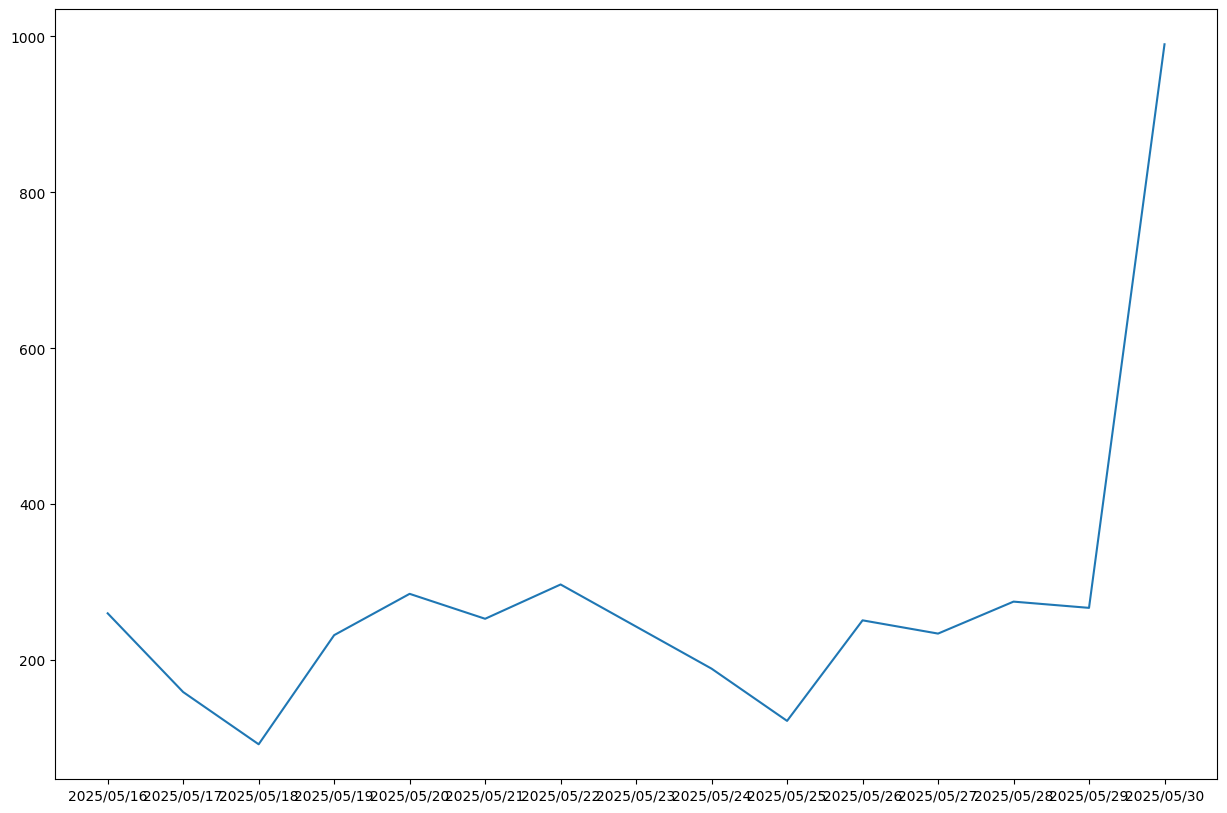

In [12]:
import	seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(15,10))
sns.lineplot(serie_coches_dia);


In [13]:
dia_correo

['2025/05/28',
 '2025/05/19',
 '2025/05/19',
 '2025/05/14',
 '2025/05/12',
 '2025/05/11',
 '2025/05/10',
 '2025/05/09',
 '2025/05/09']

In [14]:
df_correo

,Unnamed: 0,Titulo de noticia,Autor,Fecha,Hora,Fin_de_semana,Accidente,Atasco
0,0,"Cada vez somos más cívicos, pero el 50 % de lo...",Patxi Fernández,2025-05-28,11:27,0,1,1
1,1,Para a consultar a una patrulla de la Ertzaint...,H. Rodríguez,2025-05-19,10:15,0,1,1
2,2,Cuatro hombres se pegan tras un accidente de t...,David González,2025-05-19,00:20,0,1,1
3,3,Una colisión entre un camión y un coche obliga...,Nuria Nuño,2025-05-14,10:41,0,1,1
4,4,Una persona resulta herida en un accidente múl...,Leire Moro,2025-05-12,11:51,0,1,1
5,5,Un accidente en la entrada a Bilbao por San Ma...,Laura González,2025-05-11,12:52,1,1,1
6,6,Corte de carril en la autovía N-622 en Álava t...,Saioa Echeazarra,2025-05-10,08:45,1,1,1
7,7,"3,7 millones por el atropello de un niño: la m...",Rocío Mendoza| Madrid,2025-05-09,19:53,0,1,1
8,8,Un herido al volcar su furgoneta en la AP-68 a...,Nuria Nuño,2025-05-09,15:55,0,1,1


Si, parece que hay dias que cuando hay  noticias de trafico tiene un flujo menor el dia 10 y 11 aunque estos dias son fines de semana.

PD Mirando el domingo parece que es normal haya poco trafico. No se porque el hoy tiene un pico de trafico y el resto no. Puede que sea por a pillado justo la hora de mas trafico en las primeras 5 horas.
PPD. Me he dado cuenta que solo coge las 5 hojas esto seria mejor hacerlo con dlt y paginate pero no he tenido tiempo para mirarmelo bien y no me funciona el codigo